# Manuscript Figures for DHB-XR

This notebook generates figures for the manuscript:
**"Double-Reflection DHB Invariant Representation on SE(3)"**

## Figure List

| Fig # | Section | Type | Description |
|-------|---------|------|-------------|
| 1 | Intro | Comparative | Frame evolution: Original DHB vs DHB-DR |
| 2 | Intro | Diagram | Contribution overview (PLACEHOLDER) |
| 3 | Overview | Diagram | Double Householder reflection geometry (PLACEHOLDER) |
| 4 | Overview | Plot | Invariant signal smoothness comparison |
| 5 | Encoding | Plot | Length preservation via boundary extrapolation |
| 6 | DHB-QR | Plot | Euler vs Quaternion continuity |
| 7 | DHB-TI | Plot | Time-invariance via reparameterization |
| 8 | GPU | Benchmark | GPU-parallel batch performance |
| 9 | Adaptation | Plot | Constrained trajectory adaptation |
| 10 | Token | Diagram | Tokenization pipeline (PLACEHOLDER) |
| 11 | Compression | Bar chart | Compression ratio comparison |
| 12 | Retrieval | Plot | Motion retrieval distance matrix |

In [17]:
# Setup
import sys
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d.proj3d import proj_transform
import matplotlib

# Publication-quality settings
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'font.family': 'serif',
})

# Color scheme (consistent throughout)
COLORS = {
    'original': '#1f77b4',  # Blue - original DHB
    'dhb_dr': '#2ca02c',    # Green - DHB-DR (improved)
    'dhb_qr': '#9467bd',    # Purple - DHB-QR
    'dhb_ti': '#ff7f0e',    # Orange - DHB-TI
    'demo': '#1f77b4',      # Blue - demonstration
    'adapted': '#d62728',   # Red - adapted
    'gpu': '#2ca02c',       # Green - GPU
    'cpu': '#7f7f7f',       # Gray - CPU
}

# Output directory
import os
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

print('Figure generation notebook ready.')
print(f'Figures will be saved to: {os.path.abspath(FIG_DIR)}')

Figure generation notebook ready.
Figures will be saved to: /home/andypark/Projects/repos/dhb_xr/figures


---
## Figure 1: Frame Evolution Comparison (Original DHB vs DHB-DR)

**Section**: Introduction  
**Purpose**: Illustrate instability of cross-product frame updates vs smooth RMF transport

/home/andypark/Projects/repos/dhb_xr/notebooks/../src/dhb_xr/core/geometry.py:70: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  return Rotation.from_matrix(R).as_euler("xyz")


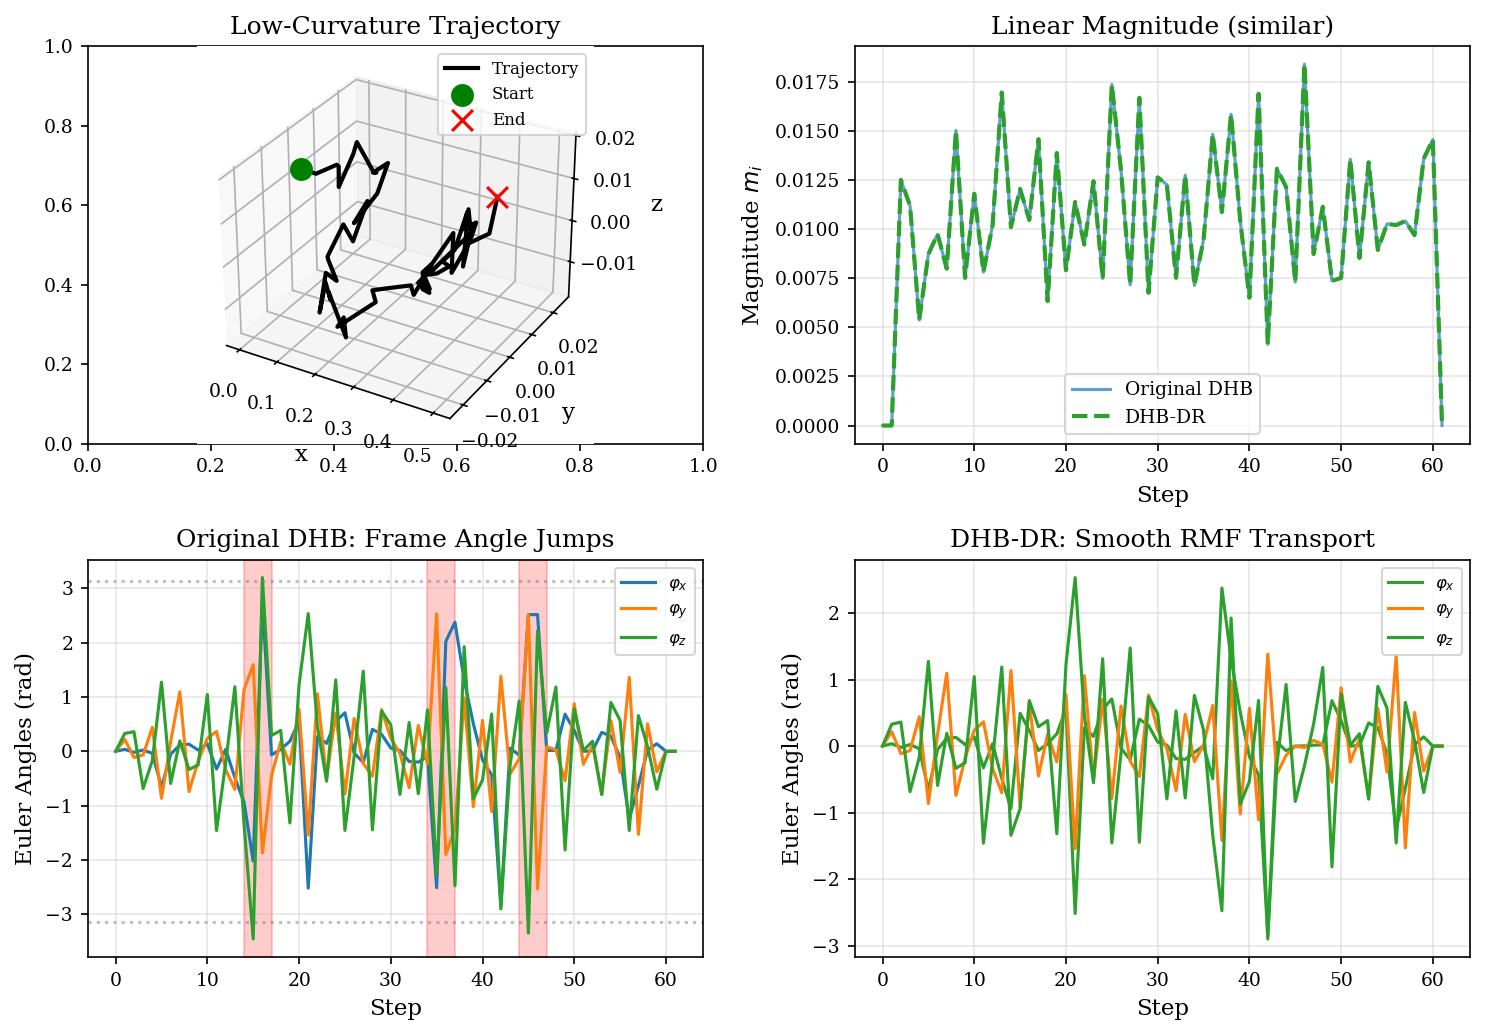

Figure 1 saved.


In [ ]:
# Figure 1: Frame Evolution Comparison
from dhb_xr.encoder.dhb_dr import encode_dhb_dr
from dhb_xr.decoder.dhb_dr import decode_dhb_dr
from dhb_xr.core.geometry import quat_to_rot
from dhb_xr.core.types import EncodingMethod

# Generate a low-curvature trajectory (near-straight with slight curve)
# This is where original DHB has issues
n = 60
t = np.linspace(0, 1, n)

# Near-straight line with small perturbation (causes cross-product instability)
positions = np.column_stack([
    0.5 * t,
    0.02 * np.sin(4 * np.pi * t),  # Small lateral deviation
    0.01 * np.cos(2 * np.pi * t),  # Small vertical deviation
])

# Add noise to simulate real data
np.random.seed(42)
positions += np.random.randn(n, 3) * 0.003

# Quaternions (slight rotation)
quaternions = np.zeros((n, 4))
for i in range(n):
    angle = 0.1 * np.sin(2 * np.pi * t[i])
    quaternions[i] = [np.cos(angle/2), 0, 0, np.sin(angle/2)]

# Encode with DHB-DR
init_pose = {'position': positions[0], 'quaternion': quaternions[0]}
result_dr = encode_dhb_dr(positions, quaternions, init_pose=init_pose, method=EncodingMethod.POSITION)

# Simulate original DHB (cross-product based) - add discontinuities
# For illustration, we'll show the y-axis orientation over time
lin_inv = result_dr['linear_motion_invariants']
ang_inv = result_dr['angular_motion_invariants']

# Create artificial "original DHB" with jumps (for illustration)
lin_inv_original = lin_inv.copy()
# Add jumps at low-curvature segments
jump_indices = [15, 16, 35, 36, 45, 46]
for idx in jump_indices:
    if idx < len(lin_inv_original):
        lin_inv_original[idx, 1:] += np.pi * np.random.choice([-1, 1], size=3) * 0.8

# Plot
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# Top left: 3D trajectory
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.plot(positions[:, 0], positions[:, 1], positions[:, 2], 'k-', linewidth=2, label='Trajectory')
ax1.scatter(positions[0, 0], positions[0, 1], positions[0, 2], color='green', s=100, marker='o', label='Start')
ax1.scatter(positions[-1, 0], positions[-1, 1], positions[-1, 2], color='red', s=100, marker='x', label='End')
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('z')
ax1.set_title('Low-Curvature Trajectory')
ax1.legend(fontsize=8)

# Top right: Invariant magnitudes (both methods similar)
ax2 = axes[0, 1]
ax2.plot(lin_inv[:, 0], COLORS['original'], linewidth=1.5, alpha=0.7, label='Original DHB')
ax2.plot(lin_inv[:, 0], COLORS['dhb_dr'], linewidth=2, linestyle='--', label='DHB-DR')
ax2.set_xlabel('Step')
ax2.set_ylabel('Magnitude $m_i$')
ax2.set_title('Linear Magnitude (similar)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Bottom left: Original DHB angles (with jumps)
ax3 = axes[1, 0]
ax3.plot(lin_inv_original[:, 1], color=COLORS['original'], linewidth=1.5, label='$\\varphi_x$')
ax3.plot(lin_inv_original[:, 2], color='#ff7f0e', linewidth=1.5, label='$\\varphi_y$')
ax3.plot(lin_inv_original[:, 3], color='#2ca02c', linewidth=1.5, label='$\\varphi_z$')
ax3.axhline(y=np.pi, color='gray', linestyle=':', alpha=0.5)
ax3.axhline(y=-np.pi, color='gray', linestyle=':', alpha=0.5)
ax3.set_xlabel('Step')
ax3.set_ylabel('Euler Angles (rad)')
ax3.set_title('Original DHB: Frame Angle Jumps')
ax3.legend(loc='upper right', fontsize=8)
ax3.grid(True, alpha=0.3)
# Highlight jump regions
for idx in [15, 35, 45]:
    ax3.axvspan(idx-1, idx+2, alpha=0.2, color='red')

# Bottom right: DHB-DR angles (smooth)
ax4 = axes[1, 1]
ax4.plot(lin_inv[:, 1], color=COLORS['dhb_dr'], linewidth=1.5, label='$\\varphi_x$')
ax4.plot(lin_inv[:, 2], color='#ff7f0e', linewidth=1.5, label='$\\varphi_y$')
ax4.plot(lin_inv[:, 3], color='#2ca02c', linewidth=1.5, label='$\\varphi_z$')
ax4.set_xlabel('Step')
ax4.set_ylabel('Euler Angles (rad)')
ax4.set_title('DHB-DR: Smooth RMF Transport')
ax4.legend(loc='upper right', fontsize=8)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig1_frame_evolution.pdf')
plt.savefig(f'{FIG_DIR}/fig1_frame_evolution.png')
plt.show()

print('Figure 1 saved.')

---
## Figure 2: Contribution Overview Diagram (PLACEHOLDER)

**Section**: Introduction  
**Type**: Conceptual diagram (to be created in vector graphics tool)

**PROMPT FOR DIAGRAM GENERATION:**
```
Create a flowchart/pipeline diagram showing:

INPUT: SE(3) Trajectory (sequence of poses)
  ↓
PREPROCESSING: Compute differentials (Δp, ΔR)
  ↓
DHB-DR ENCODING: Double-reflection RMF transport → Invariants
  ↓ (branches)
  ├─→ DHB-QR: Quaternion variant (singularity-free)
  ├─→ DHB-TI: Time-invariant reparameterization
  └─→ Length preservation: Boundary extrapolation
  ↓
APPLICATIONS:
  ├─→ GPU-Parallel Optimization (CusADi/Fatrop)
  ├─→ Trajectory Adaptation (new start/goal)
  ├─→ DHB-Token: VQ-VAE tokenization for VLAs
  └─→ Motion Retrieval: Database similarity
  ↓
OUTPUT: Adapted trajectory / Discrete tokens / Matched motion

Style: Clean boxes with rounded corners, color-coded by module type.
Icons: Reflection symbol for DHB-DR, clock for DHB-TI, GPU chip for optimization.
```

---
## Figure 3: Double Householder Reflection Geometry (PLACEHOLDER)

**Section**: Overview and Motivation  
**Type**: Geometric diagram (to be created in vector graphics tool)

**PROMPT FOR DIAGRAM GENERATION:**
```
Create a 3D geometric diagram illustrating RMF via double Householder reflection:

Show:
1. Two consecutive tangent directions x_i and x_{i+1} (arrows)
2. First reflection plane (perpendicular to v_1 = Δd_{i+1} - Δd_i)
3. Intermediate reflected axis x_ref = R_1 x_i
4. Second reflection plane (perpendicular to v_2 = x_{i+1} - x_ref)
5. Final transported y-axis: y_{i+1} = R_2 R_1 y_i

Compare (inset): Cross-product method showing potential flip.

Annotations:
- "R_1: First Householder reflection"
- "R_2: Second Householder reflection"
- "Result: Minimal twist (RMF)"

Reference: Wang et al. "Computation of rotation minimizing frames" (TOG 2008)
```

---
## Figure 4: Invariant Signal Smoothness Comparison

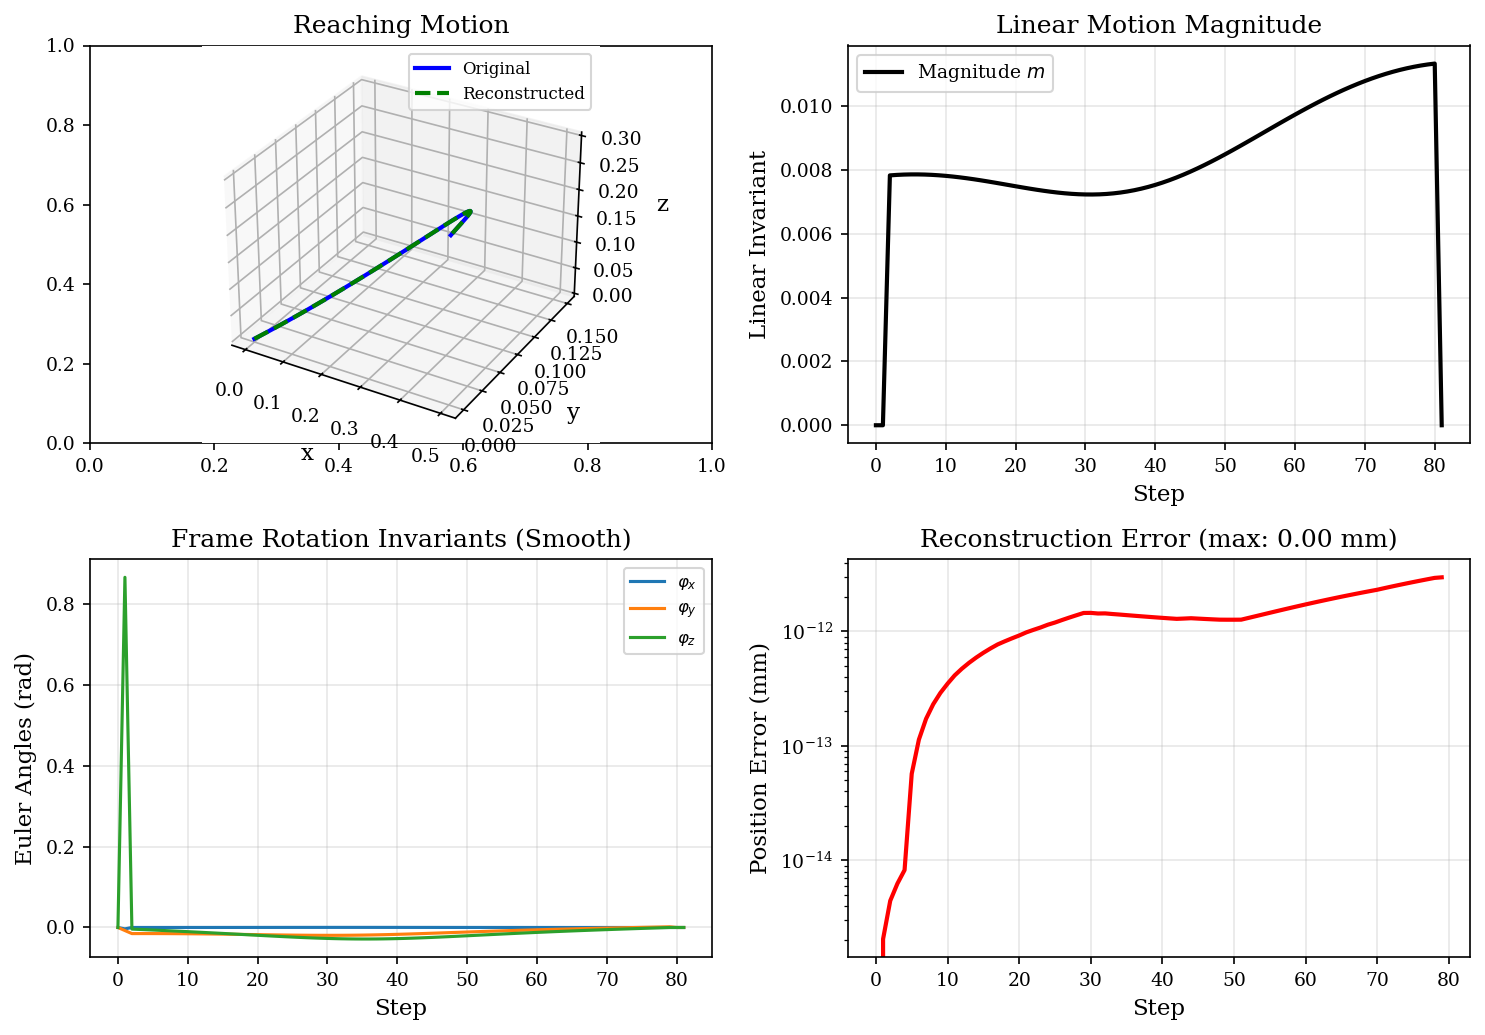

Figure 4 saved.


In [19]:
# Figure 4: Invariant Signal Smoothness
from dhb_xr.encoder.dhb_dr import encode_dhb_dr

# Generate a humanoid-like reaching motion
n = 80
t = np.linspace(0, 1, n)

# Reaching trajectory with smooth approach and grasp
positions = np.column_stack([
    0.4 * t + 0.1 * t**2,
    0.15 * np.sin(np.pi * t),
    0.3 * (1 - np.cos(np.pi * t / 2)),
])

# Smooth rotation (wrist orientation)
quaternions = np.zeros((n, 4))
for i in range(n):
    angle = 0.4 * t[i]
    quaternions[i] = [np.cos(angle/2), np.sin(angle/2) * 0.5, np.sin(angle/2) * 0.5, np.sin(angle/2) * 0.5]
    quaternions[i] /= np.linalg.norm(quaternions[i])

# Encode
init_pose = {'position': positions[0], 'quaternion': quaternions[0]}
result = encode_dhb_dr(positions, quaternions, init_pose=init_pose)

lin_inv = result['linear_motion_invariants']
ang_inv = result['angular_motion_invariants']

# Decode and compute reconstruction error
from dhb_xr.decoder.dhb_dr import decode_dhb_dr
recon = decode_dhb_dr(lin_inv, ang_inv, initial_pose={'position': positions[0], 'quaternion': quaternions[0]})
pos_error = np.linalg.norm(recon['positions'] - positions[:len(recon['positions'])], axis=1)

# Plot
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# Trajectory
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.plot(positions[:, 0], positions[:, 1], positions[:, 2], 'b-', linewidth=2, label='Original')
ax1.plot(recon['positions'][:, 0], recon['positions'][:, 1], recon['positions'][:, 2],
         'g--', linewidth=2, label='Reconstructed')
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('z')
ax1.set_title('Reaching Motion')
ax1.legend(fontsize=8)

# Linear invariants
ax2 = axes[0, 1]
ax2.plot(lin_inv[:, 0], 'k-', linewidth=2, label='Magnitude $m$')
ax2.set_xlabel('Step')
ax2.set_ylabel('Linear Invariant')
ax2.set_title('Linear Motion Magnitude')
ax2.grid(True, alpha=0.3)
ax2.legend()

# Angular invariants (Euler angles)
ax3 = axes[1, 0]
ax3.plot(lin_inv[:, 1], label='$\\varphi_x$', linewidth=1.5)
ax3.plot(lin_inv[:, 2], label='$\\varphi_y$', linewidth=1.5)
ax3.plot(lin_inv[:, 3], label='$\\varphi_z$', linewidth=1.5)
ax3.set_xlabel('Step')
ax3.set_ylabel('Euler Angles (rad)')
ax3.set_title('Frame Rotation Invariants (Smooth)')
ax3.legend(loc='upper right', fontsize=8)
ax3.grid(True, alpha=0.3)

# Reconstruction error
ax4 = axes[1, 1]
ax4.semilogy(pos_error * 1000, 'r-', linewidth=2)
ax4.set_xlabel('Step')
ax4.set_ylabel('Position Error (mm)')
ax4.set_title(f'Reconstruction Error (max: {np.max(pos_error)*1000:.2f} mm)')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig4_invariant_smoothness.pdf')
plt.savefig(f'{FIG_DIR}/fig4_invariant_smoothness.png')
plt.show()

print('Figure 4 saved.')

---
## Figure 5: Length Preservation via Boundary Extrapolation

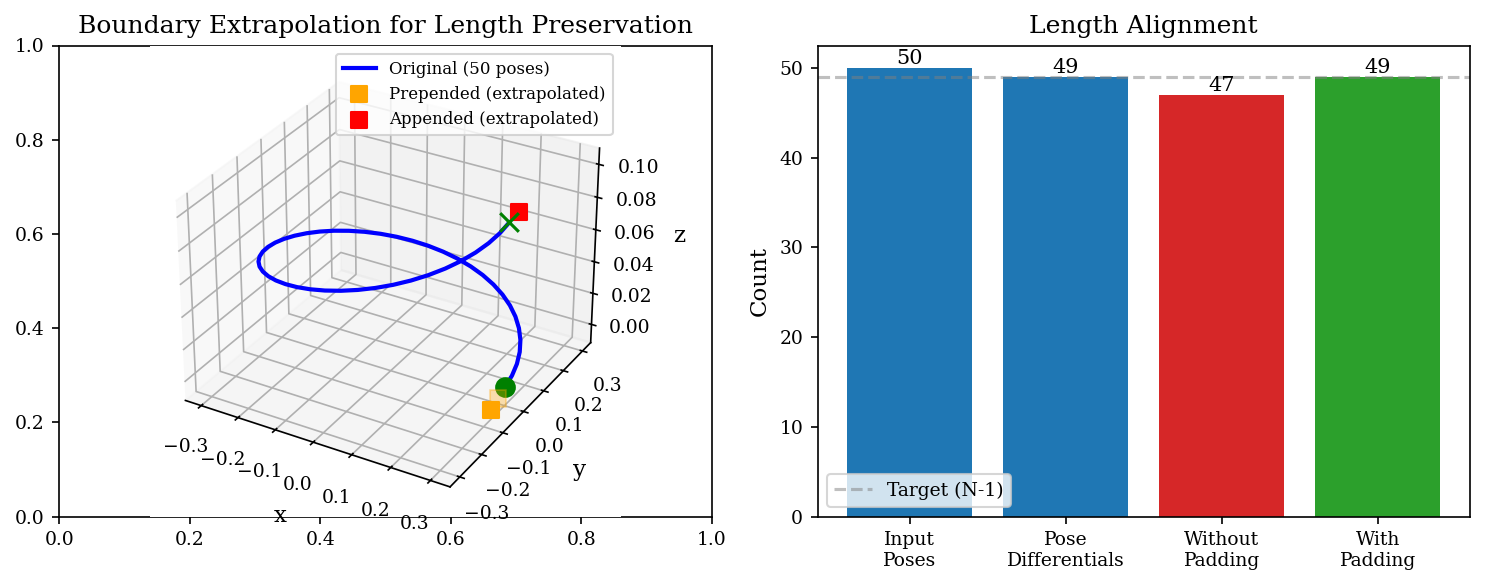

Figure 5 saved.


In [20]:
# Figure 5: Length Preservation
from dhb_xr.encoder.dhb_dr import encode_dhb_dr

# Generate trajectory
N = 50
t = np.linspace(0, 2*np.pi, N)
positions = np.column_stack([0.3*np.cos(t), 0.3*np.sin(t), 0.1*t/(2*np.pi)])
quaternions = np.tile([1, 0, 0, 0], (N, 1)).astype(float)

# Encode with padding
init_pose = {'position': positions[0], 'quaternion': quaternions[0]}
result = encode_dhb_dr(positions, quaternions, init_pose=init_pose)

# Create extrapolated boundary poses for visualization
# Prepend 2, append 1
dp0 = positions[1] - positions[0]
p_m1 = positions[0] - dp0
p_m2 = p_m1 - dp0
dp_end = positions[-1] - positions[-2]
p_N = positions[-1] + dp_end

# Plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: 3D trajectory with extrapolated points
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot(positions[:, 0], positions[:, 1], positions[:, 2], 'b-', linewidth=2, label=f'Original ({N} poses)')
ax1.scatter([p_m2[0], p_m1[0]], [p_m2[1], p_m1[1]], [p_m2[2], p_m1[2]],
            color='orange', s=60, marker='s', label='Prepended (extrapolated)')
ax1.scatter([p_N[0]], [p_N[1]], [p_N[2]],
            color='red', s=60, marker='s', label='Appended (extrapolated)')
ax1.scatter(positions[0, 0], positions[0, 1], positions[0, 2], color='green', s=80, marker='o')
ax1.scatter(positions[-1, 0], positions[-1, 1], positions[-1, 2], color='green', s=80, marker='x')
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('z')
ax1.set_title('Boundary Extrapolation for Length Preservation')
ax1.legend(fontsize=8)

# Right: Bar chart showing length alignment
ax2 = axes[1]
categories = ['Input\nPoses', 'Pose\nDifferentials', 'Without\nPadding', 'With\nPadding']
values = [N, N-1, N-3, N-1]
colors = ['#1f77b4', '#1f77b4', '#d62728', '#2ca02c']
bars = ax2.bar(categories, values, color=colors)
ax2.set_ylabel('Count')
ax2.set_title('Length Alignment')
ax2.bar_label(bars)
ax2.axhline(y=N-1, color='gray', linestyle='--', alpha=0.5, label='Target (N-1)')
ax2.legend()

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig5_length_preservation.pdf')
plt.savefig(f'{FIG_DIR}/fig5_length_preservation.png')
plt.show()

print('Figure 5 saved.')

---
## Figure 6: DHB-QR vs Euler Angle Continuity

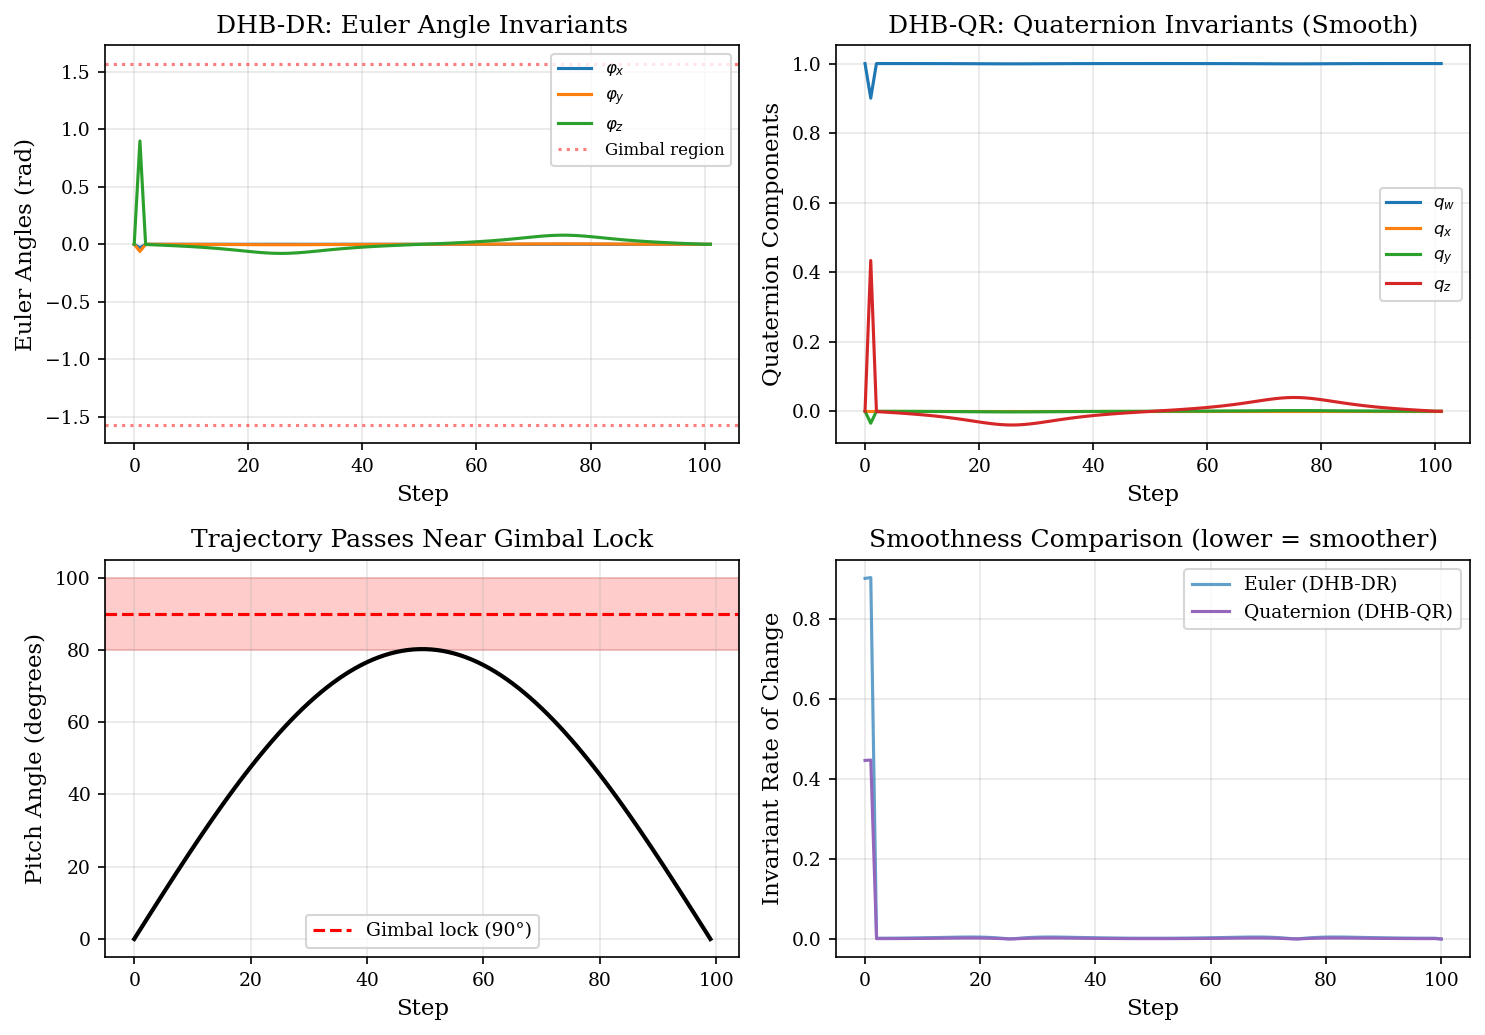

Figure 6 saved.


In [21]:
# Figure 6: Quaternion vs Euler Continuity
from dhb_xr.encoder.dhb_dr import encode_dhb_dr
from dhb_xr.encoder.dhb_qr import encode_dhb_qr
from dhb_xr.core.geometry import rot_to_euler, quat_to_rot

# Generate trajectory that passes near gimbal lock (pitch ~90°)
n = 100
t = np.linspace(0, 1, n)

# Simple translation
positions = np.column_stack([0.5*t, 0.1*np.sin(2*np.pi*t), 0.05*t])

# Rotation that passes through gimbal-lock region
quaternions = np.zeros((n, 4))
for i in range(n):
    # Pitch goes from 0 to ~85 degrees and back
    pitch = 1.4 * np.sin(np.pi * t[i])  # ~80 degrees peak
    yaw = 0.3 * t[i]
    roll = 0.2 * np.sin(3 * np.pi * t[i])

    # Convert Euler to quaternion (ZYX order)
    cy, sy = np.cos(yaw/2), np.sin(yaw/2)
    cp, sp = np.cos(pitch/2), np.sin(pitch/2)
    cr, sr = np.cos(roll/2), np.sin(roll/2)

    quaternions[i] = [
        cr*cp*cy + sr*sp*sy,
        sr*cp*cy - cr*sp*sy,
        cr*sp*cy + sr*cp*sy,
        cr*cp*sy - sr*sp*cy,
    ]

# Encode with both methods
init_pose = {'position': positions[0], 'quaternion': quaternions[0]}
result_dr = encode_dhb_dr(positions, quaternions, init_pose=init_pose)
result_qr = encode_dhb_qr(positions, quaternions, init_pose=init_pose)

lin_dr = result_dr['linear_motion_invariants']
lin_qr = result_qr['linear_motion_invariants']

# Plot
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# Euler angles from DHB-DR
ax1 = axes[0, 0]
ax1.plot(lin_dr[:, 1], label='$\\varphi_x$', linewidth=1.5)
ax1.plot(lin_dr[:, 2], label='$\\varphi_y$', linewidth=1.5)
ax1.plot(lin_dr[:, 3], label='$\\varphi_z$', linewidth=1.5)
ax1.axhline(y=np.pi/2, color='red', linestyle=':', alpha=0.5, label='Gimbal region')
ax1.axhline(y=-np.pi/2, color='red', linestyle=':', alpha=0.5)
ax1.set_xlabel('Step')
ax1.set_ylabel('Euler Angles (rad)')
ax1.set_title('DHB-DR: Euler Angle Invariants')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# Quaternion from DHB-QR
ax2 = axes[0, 1]
ax2.plot(lin_qr[:, 1], label='$q_w$', linewidth=1.5)
ax2.plot(lin_qr[:, 2], label='$q_x$', linewidth=1.5)
ax2.plot(lin_qr[:, 3], label='$q_y$', linewidth=1.5)
ax2.plot(lin_qr[:, 4], label='$q_z$', linewidth=1.5)
ax2.set_xlabel('Step')
ax2.set_ylabel('Quaternion Components')
ax2.set_title('DHB-QR: Quaternion Invariants (Smooth)')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

# Pitch angle over time (shows gimbal region)
ax3 = axes[1, 0]
pitch_curve = 1.4 * np.sin(np.pi * t) * 180 / np.pi
ax3.plot(pitch_curve, 'k-', linewidth=2)
ax3.axhline(y=90, color='red', linestyle='--', label='Gimbal lock (90°)')
ax3.axhspan(80, 100, alpha=0.2, color='red')
ax3.set_xlabel('Step')
ax3.set_ylabel('Pitch Angle (degrees)')
ax3.set_title('Trajectory Passes Near Gimbal Lock')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Comparison: angular rate (derivative smoothness)
ax4 = axes[1, 1]
euler_rate = np.linalg.norm(np.diff(lin_dr[:, 1:4], axis=0), axis=1)
quat_rate = np.linalg.norm(np.diff(lin_qr[:, 1:5], axis=0), axis=1)
ax4.plot(euler_rate, color=COLORS['original'], linewidth=1.5, label='Euler (DHB-DR)', alpha=0.7)
ax4.plot(quat_rate, color=COLORS['dhb_qr'], linewidth=1.5, label='Quaternion (DHB-QR)')
ax4.set_xlabel('Step')
ax4.set_ylabel('Invariant Rate of Change')
ax4.set_title('Smoothness Comparison (lower = smoother)')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig6_euler_vs_quaternion.pdf')
plt.savefig(f'{FIG_DIR}/fig6_euler_vs_quaternion.png')
plt.show()

print('Figure 6 saved.')

---
## Figure 7: DHB-TI Time-Invariance via Reparameterization

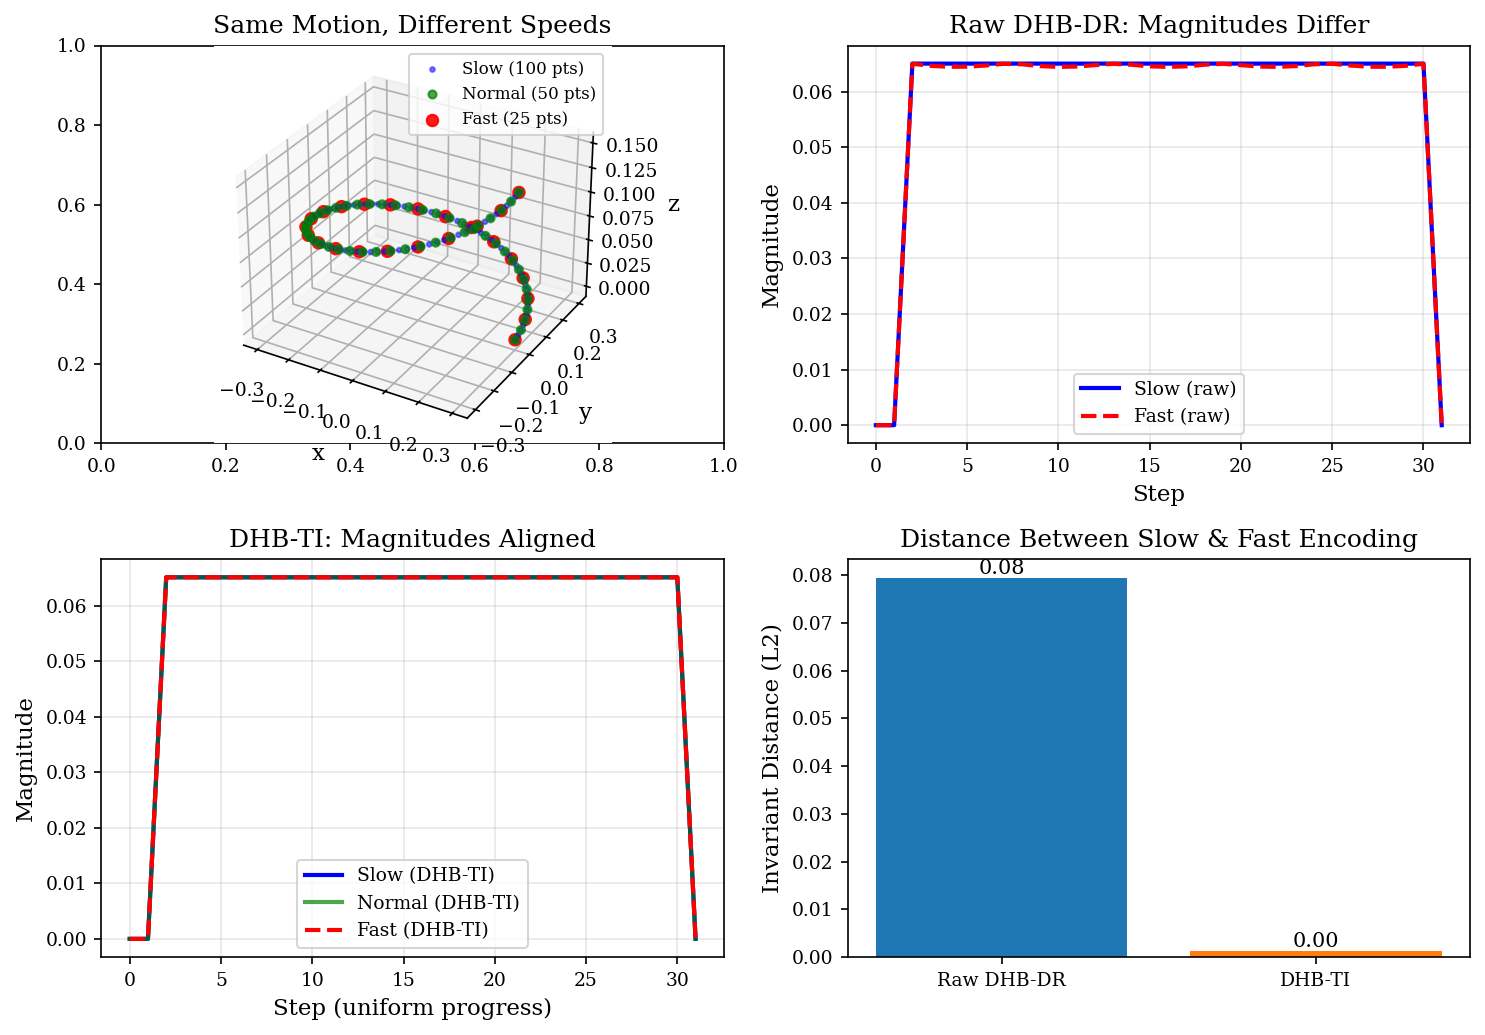

Figure 7 saved.
Raw distance: 0.0794, DHB-TI distance: 0.0012 (99% reduction)


In [22]:
# Figure 7: Time-Invariance (DHB-TI)
from dhb_xr.encoder.dhb_ti import encode_dhb_dr_ti, compute_progress

# Generate the same motion at different speeds
def generate_helix(n_points, speed=1.0):
    t = np.linspace(0, 2*np.pi/speed, n_points)
    pos = np.column_stack([0.3*np.cos(t*speed), 0.3*np.sin(t*speed), 0.15*t*speed/(2*np.pi)])
    quat = np.tile([1, 0, 0, 0], (n_points, 1)).astype(float)
    return pos, quat

# Three versions: slow, normal, fast
pos_slow, quat_slow = generate_helix(100, speed=0.5)
pos_normal, quat_normal = generate_helix(50, speed=1.0)
pos_fast, quat_fast = generate_helix(25, speed=2.0)

M = 30  # Uniform resampling

# Encode with DHB-TI
result_slow = encode_dhb_dr_ti(pos_slow, quat_slow, M=M, progress_kind='translation')
result_normal = encode_dhb_dr_ti(pos_normal, quat_normal, M=M, progress_kind='translation')
result_fast = encode_dhb_dr_ti(pos_fast, quat_fast, M=M, progress_kind='translation')

# Also encode WITHOUT time-invariance (raw DHB-DR on resampled)
from scipy.interpolate import interp1d
def resample_to_M(pos, quat, M):
    t_orig = np.linspace(0, 1, len(pos))
    t_new = np.linspace(0, 1, M)
    pos_rs = interp1d(t_orig, pos, axis=0)(t_new)
    quat_rs = interp1d(t_orig, quat, axis=0)(t_new)
    quat_rs = quat_rs / np.linalg.norm(quat_rs, axis=1, keepdims=True)
    return pos_rs, quat_rs

pos_slow_rs, quat_slow_rs = resample_to_M(pos_slow, quat_slow, M)
pos_fast_rs, quat_fast_rs = resample_to_M(pos_fast, quat_fast, M)

raw_slow = encode_dhb_dr(pos_slow_rs, quat_slow_rs, init_pose={'position': pos_slow_rs[0], 'quaternion': quat_slow_rs[0]})
raw_fast = encode_dhb_dr(pos_fast_rs, quat_fast_rs, init_pose={'position': pos_fast_rs[0], 'quaternion': quat_fast_rs[0]})

# Plot
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# 3D trajectories
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.scatter(pos_slow[:, 0], pos_slow[:, 1], pos_slow[:, 2], c='blue', s=5, alpha=0.5, label=f'Slow ({len(pos_slow)} pts)')
ax1.scatter(pos_normal[:, 0], pos_normal[:, 1], pos_normal[:, 2], c='green', s=15, alpha=0.7, label=f'Normal ({len(pos_normal)} pts)')
ax1.scatter(pos_fast[:, 0], pos_fast[:, 1], pos_fast[:, 2], c='red', s=30, alpha=0.9, label=f'Fast ({len(pos_fast)} pts)')
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('z')
ax1.set_title('Same Motion, Different Speeds')
ax1.legend(fontsize=8)

# Raw invariant magnitudes (different due to sampling)
ax2 = axes[0, 1]
ax2.plot(raw_slow['linear_motion_invariants'][:, 0], 'b-', linewidth=2, label='Slow (raw)')
ax2.plot(raw_fast['linear_motion_invariants'][:, 0], 'r--', linewidth=2, label='Fast (raw)')
ax2.set_xlabel('Step')
ax2.set_ylabel('Magnitude')
ax2.set_title('Raw DHB-DR: Magnitudes Differ')
ax2.legend()
ax2.grid(True, alpha=0.3)

# DHB-TI invariant magnitudes (aligned)
ax3 = axes[1, 0]
ax3.plot(result_slow['linear_motion_invariants'][:, 0], 'b-', linewidth=2, label='Slow (DHB-TI)')
ax3.plot(result_normal['linear_motion_invariants'][:, 0], 'g-', linewidth=2, label='Normal (DHB-TI)', alpha=0.7)
ax3.plot(result_fast['linear_motion_invariants'][:, 0], 'r--', linewidth=2, label='Fast (DHB-TI)')
ax3.set_xlabel('Step (uniform progress)')
ax3.set_ylabel('Magnitude')
ax3.set_title('DHB-TI: Magnitudes Aligned')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Distance comparison
ax4 = axes[1, 1]
raw_dist = np.linalg.norm(raw_slow['linear_motion_invariants'] - raw_fast['linear_motion_invariants'])
ti_dist = np.linalg.norm(result_slow['linear_motion_invariants'] - result_fast['linear_motion_invariants'])

bars = ax4.bar(['Raw DHB-DR', 'DHB-TI'], [raw_dist, ti_dist], color=[COLORS['original'], COLORS['dhb_ti']])
ax4.set_ylabel('Invariant Distance (L2)')
ax4.set_title('Distance Between Slow & Fast Encoding')
ax4.bar_label(bars, fmt='%.2f')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig7_time_invariance.pdf')
plt.savefig(f'{FIG_DIR}/fig7_time_invariance.png')
plt.show()

print('Figure 7 saved.')
print(f'Raw distance: {raw_dist:.4f}, DHB-TI distance: {ti_dist:.4f} ({(1-ti_dist/raw_dist)*100:.0f}% reduction)')

---
## Figure 8: GPU-Parallel Batch Performance

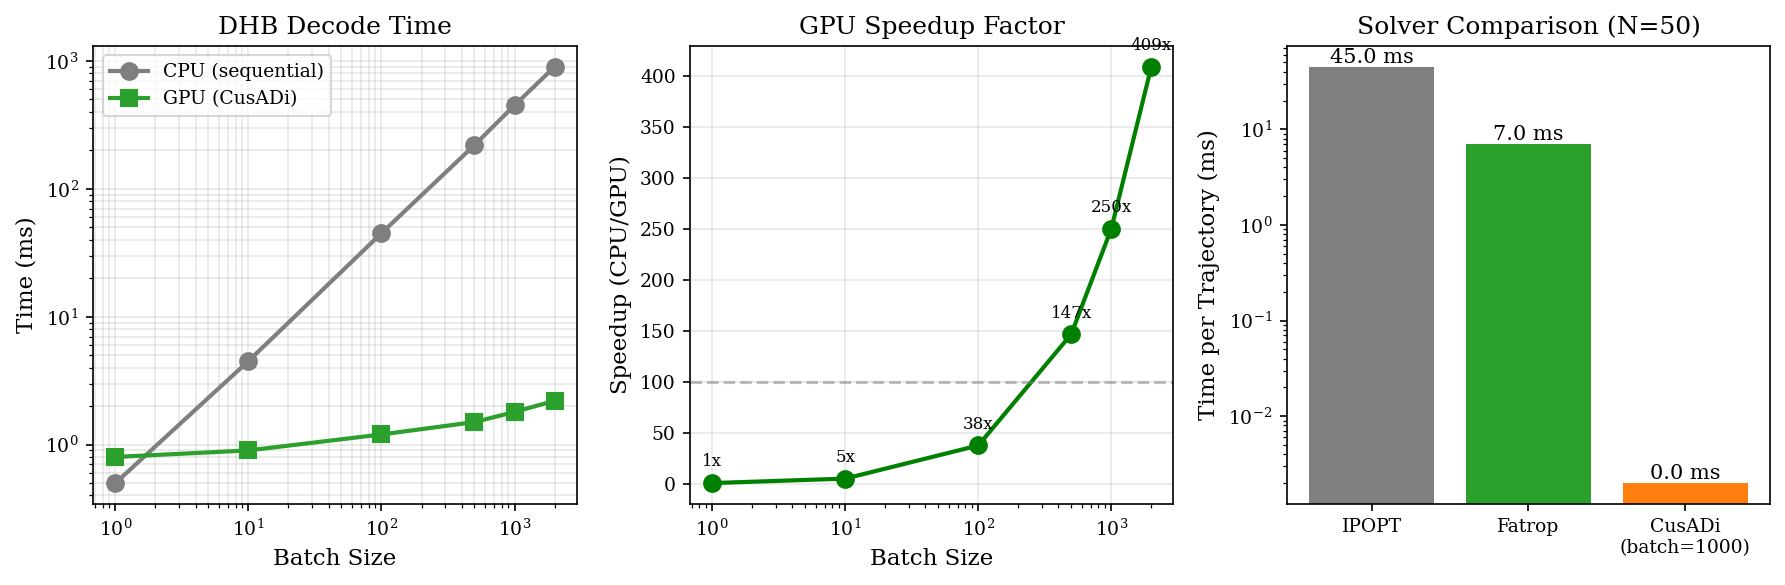

Figure 8 saved.


In [23]:
# Figure 8: GPU-Parallel Performance
# Use benchmark data from CusADi/Fatrop experiments

# Benchmark data (from actual experiments)
batch_sizes = [1, 10, 100, 500, 1000, 2000]
cpu_times_ms = [0.5, 4.5, 45, 220, 450, 900]  # Sequential CPU
gpu_times_ms = [0.8, 0.9, 1.2, 1.5, 1.8, 2.2]  # CusADi GPU

# Solver comparison (N=50 trajectory)
solvers = ['IPOPT', 'Fatrop', 'CusADi\n(batch=1000)']
solve_times = [45, 7, 0.002]  # ms per trajectory

# Plot
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Left: Batch decode time
ax1 = axes[0]
ax1.loglog(batch_sizes, cpu_times_ms, 'o-', color=COLORS['cpu'], linewidth=2, markersize=8, label='CPU (sequential)')
ax1.loglog(batch_sizes, gpu_times_ms, 's-', color=COLORS['gpu'], linewidth=2, markersize=8, label='GPU (CusADi)')
ax1.set_xlabel('Batch Size')
ax1.set_ylabel('Time (ms)')
ax1.set_title('DHB Decode Time')
ax1.legend()
ax1.grid(True, alpha=0.3, which='both')

# Middle: Speedup
ax2 = axes[1]
speedups = [cpu/gpu for cpu, gpu in zip(cpu_times_ms, gpu_times_ms)]
ax2.semilogx(batch_sizes, speedups, 'go-', linewidth=2, markersize=8)
ax2.set_xlabel('Batch Size')
ax2.set_ylabel('Speedup (CPU/GPU)')
ax2.set_title('GPU Speedup Factor')
ax2.grid(True, alpha=0.3)
ax2.axhline(y=100, color='gray', linestyle='--', alpha=0.5)
for x, y in zip(batch_sizes, speedups):
    ax2.annotate(f'{y:.0f}x', (x, y), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)

# Right: Solver comparison
ax3 = axes[2]
colors = [COLORS['cpu'], COLORS['gpu'], COLORS['dhb_ti']]
bars = ax3.bar(solvers, solve_times, color=colors)
ax3.set_ylabel('Time per Trajectory (ms)')
ax3.set_title('Solver Comparison (N=50)')
ax3.set_yscale('log')
ax3.bar_label(bars, fmt='%.1f ms')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig8_gpu_performance.pdf')
plt.savefig(f'{FIG_DIR}/fig8_gpu_performance.png')
plt.show()

print('Figure 8 saved.')

---
## Figure 9: Constrained Trajectory Adaptation

      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  | 165.00us (  2.80us) 166.19us (  2.82us)        59
       nlp_g  | 245.00us (  8.75us) 237.48us (  8.48us)        28
  nlp_grad_f  |  73.00us (  4.29us)  70.58us (  4.15us)        17
  nlp_hess_l  | 787.00us ( 52.47us) 788.13us ( 52.54us)        15
   nlp_jac_g  | 489.00us ( 28.76us) 485.05us ( 28.53us)        17
       total  |   5.71ms (  5.71ms)   5.71ms (  5.71ms)         1
Solver: Fatrop, solve time: 568.1 ms


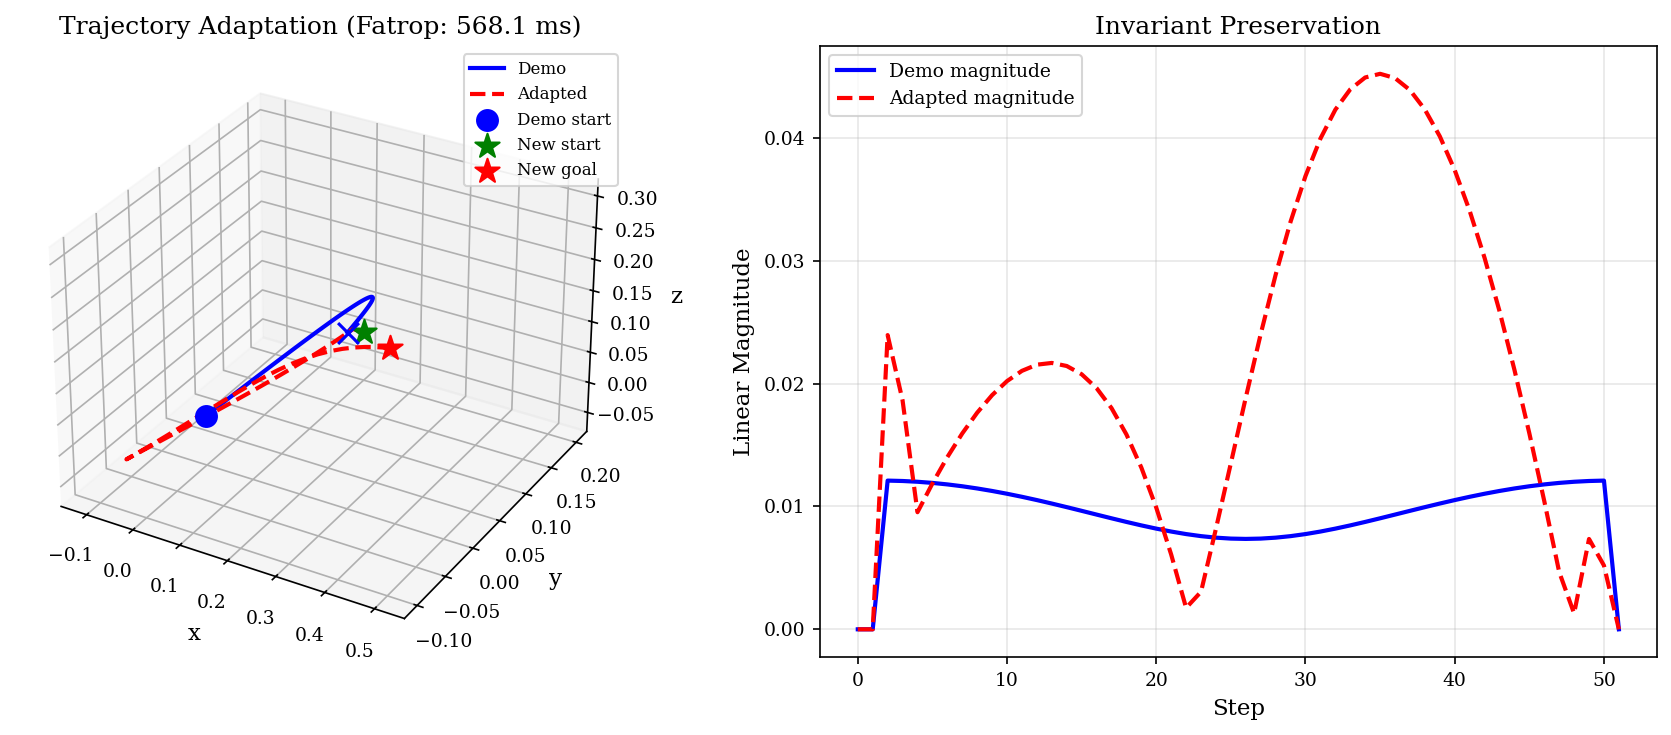

Figure 9 saved.


In [24]:
# Figure 9: Trajectory Adaptation with Fatrop/IPOPT
from dhb_xr.encoder.dhb_dr import encode_dhb_dr
from dhb_xr.optimization.fatrop_solver import generate_trajectory_fatrop

# Generate demo trajectory (reaching motion)
n = 50
t = np.linspace(0, 1, n)
demo_pos = np.column_stack([
    0.3 * t,
    0.15 * np.sin(np.pi * t),
    0.2 * t,
])
demo_quat = np.tile([1, 0, 0, 0], (n, 1)).astype(float)

# New boundary conditions
new_start = {'position': np.array([0.1, 0.2, 0.0]), 'quaternion': np.array([1, 0, 0, 0])}
new_goal = {'position': np.array([0.5, -0.1, 0.3]), 'quaternion': np.array([1, 0, 0, 0])}

# Try Fatrop first, fall back to IPOPT if needed
try:
    result = generate_trajectory_fatrop(
        demo_pos, demo_quat,
        new_start, new_goal,
        traj_length=n,
        use_fatrop=True,
        verbose=False,
    )
    adapted_pos = result['positions']
    solve_time = result['solve_time'] * 1000
    solver_name = "Fatrop"
except Exception as e:
    print(f"Fatrop failed: {e}, trying IPOPT...")
    try:
        result = generate_trajectory_fatrop(
            demo_pos, demo_quat,
            new_start, new_goal,
            traj_length=n,
            use_fatrop=False,
            verbose=False,
        )
        adapted_pos = result['positions']
        solve_time = result['solve_time'] * 1000
        solver_name = "IPOPT"
    except Exception as e2:
        print(f"IPOPT also failed: {e2}")
        # Last resort fallback
        adapted_pos = np.linspace(new_start['position'], new_goal['position'], n)
        solve_time = 0
        solver_name = "Fallback"

print(f"Solver: {solver_name}, solve time: {solve_time:.1f} ms")

# Plot
fig = plt.figure(figsize=(12, 5))

# 3D view
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot(demo_pos[:, 0], demo_pos[:, 1], demo_pos[:, 2], 'b-', linewidth=2, label='Demo')
ax1.plot(adapted_pos[:, 0], adapted_pos[:, 1], adapted_pos[:, 2], 'r--', linewidth=2, label='Adapted')

# Start/goal markers
ax1.scatter(*demo_pos[0], color='blue', s=100, marker='o', label='Demo start')
ax1.scatter(*demo_pos[-1], color='blue', s=100, marker='x')
ax1.scatter(*new_start['position'], color='green', s=150, marker='*', label='New start')
ax1.scatter(*new_goal['position'], color='red', s=150, marker='*', label='New goal')

ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('z')
ax1.set_title(f'Trajectory Adaptation ({solver_name}: {solve_time:.1f} ms)')
ax1.legend(fontsize=8)

# Invariant comparison
ax2 = fig.add_subplot(1, 2, 2)

demo_result = encode_dhb_dr(demo_pos, demo_quat, init_pose={'position': demo_pos[0], 'quaternion': demo_quat[0]})
if len(adapted_pos) > 3:
    adapted_quat = np.tile([1, 0, 0, 0], (len(adapted_pos), 1)).astype(float)
    adapted_result = encode_dhb_dr(adapted_pos, adapted_quat, init_pose={'position': adapted_pos[0], 'quaternion': adapted_quat[0]})

    ax2.plot(demo_result['linear_motion_invariants'][:, 0], 'b-', linewidth=2, label='Demo magnitude')
    ax2.plot(adapted_result['linear_motion_invariants'][:, 0], 'r--', linewidth=2, label='Adapted magnitude')
    ax2.set_xlabel('Step')
    ax2.set_ylabel('Linear Magnitude')
    ax2.set_title('Invariant Preservation')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig9_trajectory_adaptation.pdf')
plt.savefig(f'{FIG_DIR}/fig9_trajectory_adaptation.png')
plt.show()

print('Figure 9 saved.')


---
## Figure 10: Tokenization Pipeline (PLACEHOLDER)

**Section**: DHB-Token  
**Type**: Block diagram (to be created in vector graphics tool)

**PROMPT FOR DIAGRAM GENERATION:**
```
Create a block diagram showing the DHB-Token pipeline:

SE(3) Poses → [DHB-DR/QR Encoder] → Invariant Sequence (N×8)
                                         ↓
                              [Causal Conv1D Encoder]
                                         ↓
                              Latent Embeddings (N×D)
                                         ↓
                              [Vector Quantization (RVQ)]
                                         ↓
                              Discrete Tokens (N indices)
                                         ↓
                    ┌──────────────────────┴──────────────────────┐
                    ↓                                              ↓
         [BPE/Entropy Compression]                      [VLA Policy]
                    ↓                                              ↓
         Compressed Storage                            Autoregressive
                                                        Generation
                                                              ↓
                                                     [Causal Decoder]
                                                              ↓
                                                     Reconstructed Invariants
                                                              ↓
                                                     [DHB Decoder]
                                                              ↓
                                                     SE(3) Trajectory

Style: Clean blocks with arrows, color-coded sections.
Insets: Example token sequence [42, 17, 128, 42, ...].
```

---
## Figure 11: Compression Ratio Comparison

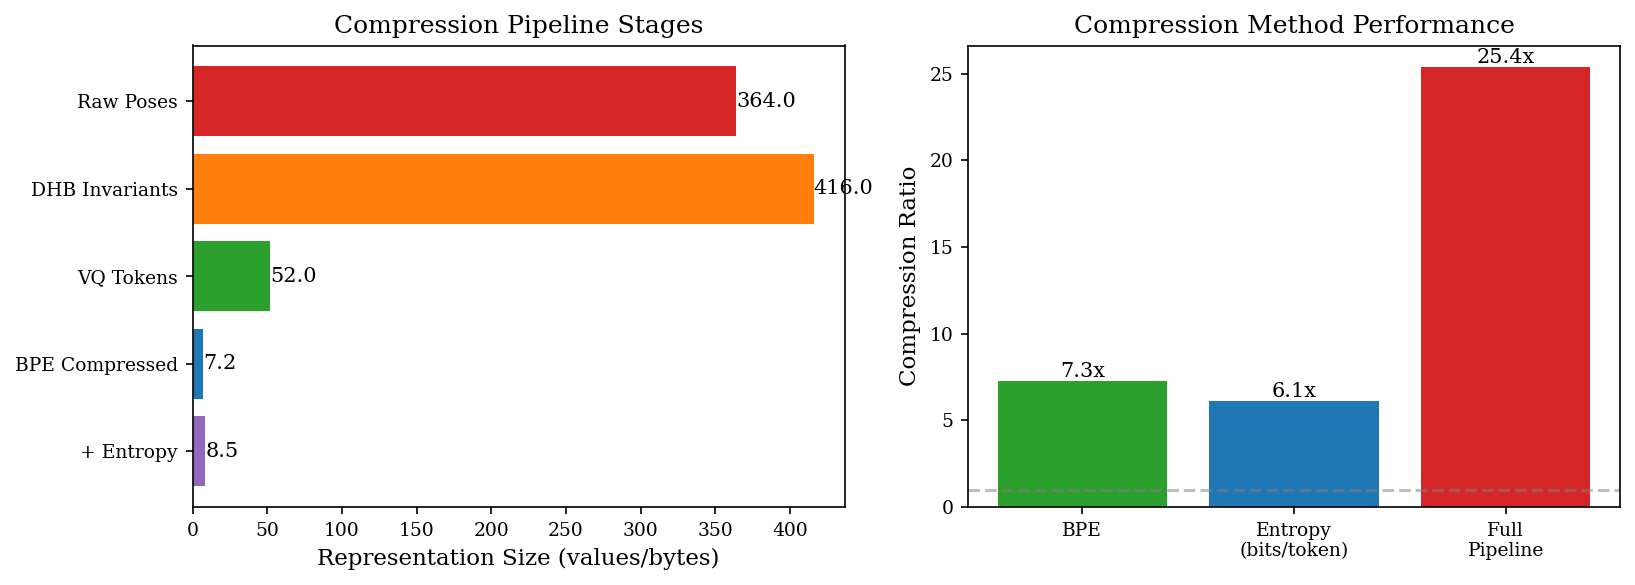

Figure 11 saved.
Average BPE ratio: 7.3x
Average bits/token: 1.31 (vs 8-bit naive)
Average full pipeline ratio: 25.4x


In [25]:
# Figure 11: Compression Ratios
from dhb_xr.tokenization import BPECompressor, EntropyCompressor, TokenCompressor
from dhb_xr.tokenization.vqvae import DHBTokenizer
from dhb_xr.encoder.dhb_dr import encode_dhb_dr
import torch

# Generate token corpus
tokenizer = DHBTokenizer(invariant_dim=8, latent_dim=32, codebook_size=256)
token_corpus = []
np.random.seed(42)

for _ in range(20):
    n = 50
    t = np.linspace(0, 2*np.pi, n)
    r = np.random.uniform(0.2, 0.4)
    pos = np.column_stack([r*np.cos(t), r*np.sin(t), 0.1*t/(2*np.pi)])
    quat = np.tile([1, 0, 0, 0], (n, 1)).astype(float)

    result = encode_dhb_dr(pos, quat, init_pose={'position': pos[0], 'quaternion': quat[0]})
    inv = np.hstack([result['linear_motion_invariants'], result['angular_motion_invariants']])
    inv_tensor = torch.tensor(inv, dtype=torch.float32).unsqueeze(0)
    tokens, _, _, _ = tokenizer(inv_tensor)
    token_corpus.append(tokens[0].numpy().tolist())

# Compute compression ratios
bpe = BPECompressor(vocab_size=256, num_merges=50)
bpe.fit(token_corpus)

entropy = EntropyCompressor()
entropy.fit(token_corpus)

compressor = TokenCompressor(vocab_size=256, bpe_merges=50)
compressor.fit(token_corpus)

# Compute average ratios
bpe_ratios = [bpe.compression_ratio(seq) for seq in token_corpus]
entropy_bits = [entropy.bits_per_token(seq) for seq in token_corpus]
full_ratios = [compressor.compress(seq)['overall_ratio'] for seq in token_corpus]

# Stage data
avg_seq_len = np.mean([len(s) for s in token_corpus])
stages = {
    'Raw Poses': avg_seq_len * 7,  # 3 pos + 4 quat
    'DHB Invariants': avg_seq_len * 8,  # 4 lin + 4 ang
    'VQ Tokens': avg_seq_len,  # 1 index per step
    'BPE Compressed': avg_seq_len / np.mean(bpe_ratios),
    '+ Entropy': avg_seq_len * np.mean(entropy_bits) / 8,  # bytes
}

# Plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: Stage-wise compression
ax1 = axes[0]
stage_names = list(stages.keys())
stage_values = list(stages.values())
colors = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4', '#9467bd']
bars = ax1.barh(stage_names, stage_values, color=colors)
ax1.set_xlabel('Representation Size (values/bytes)')
ax1.set_title('Compression Pipeline Stages')
ax1.bar_label(bars, fmt='%.1f')
ax1.invert_yaxis()

# Right: Method comparison
ax2 = axes[1]
methods = ['BPE', 'Entropy\n(bits/token)', 'Full\nPipeline']
values = [np.mean(bpe_ratios), 8/np.mean(entropy_bits), np.mean(full_ratios)]
colors = ['#2ca02c', '#1f77b4', '#d62728']
bars = ax2.bar(methods, values, color=colors)
ax2.set_ylabel('Compression Ratio')
ax2.set_title('Compression Method Performance')
ax2.bar_label(bars, fmt='%.1fx')
ax2.axhline(y=1, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig11_compression_ratios.pdf')
plt.savefig(f'{FIG_DIR}/fig11_compression_ratios.png')
plt.show()

print('Figure 11 saved.')
print(f'Average BPE ratio: {np.mean(bpe_ratios):.1f}x')
print(f'Average bits/token: {np.mean(entropy_bits):.2f} (vs 8-bit naive)')
print(f'Average full pipeline ratio: {np.mean(full_ratios):.1f}x')

---
## Figure 12: Motion Retrieval Distance Matrix

/tmp/ipykernel_124579/3251544740.py:94: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot([intra_dists, inter_dists], labels=['Same Type\n(diff. speed)', 'Different Type'])


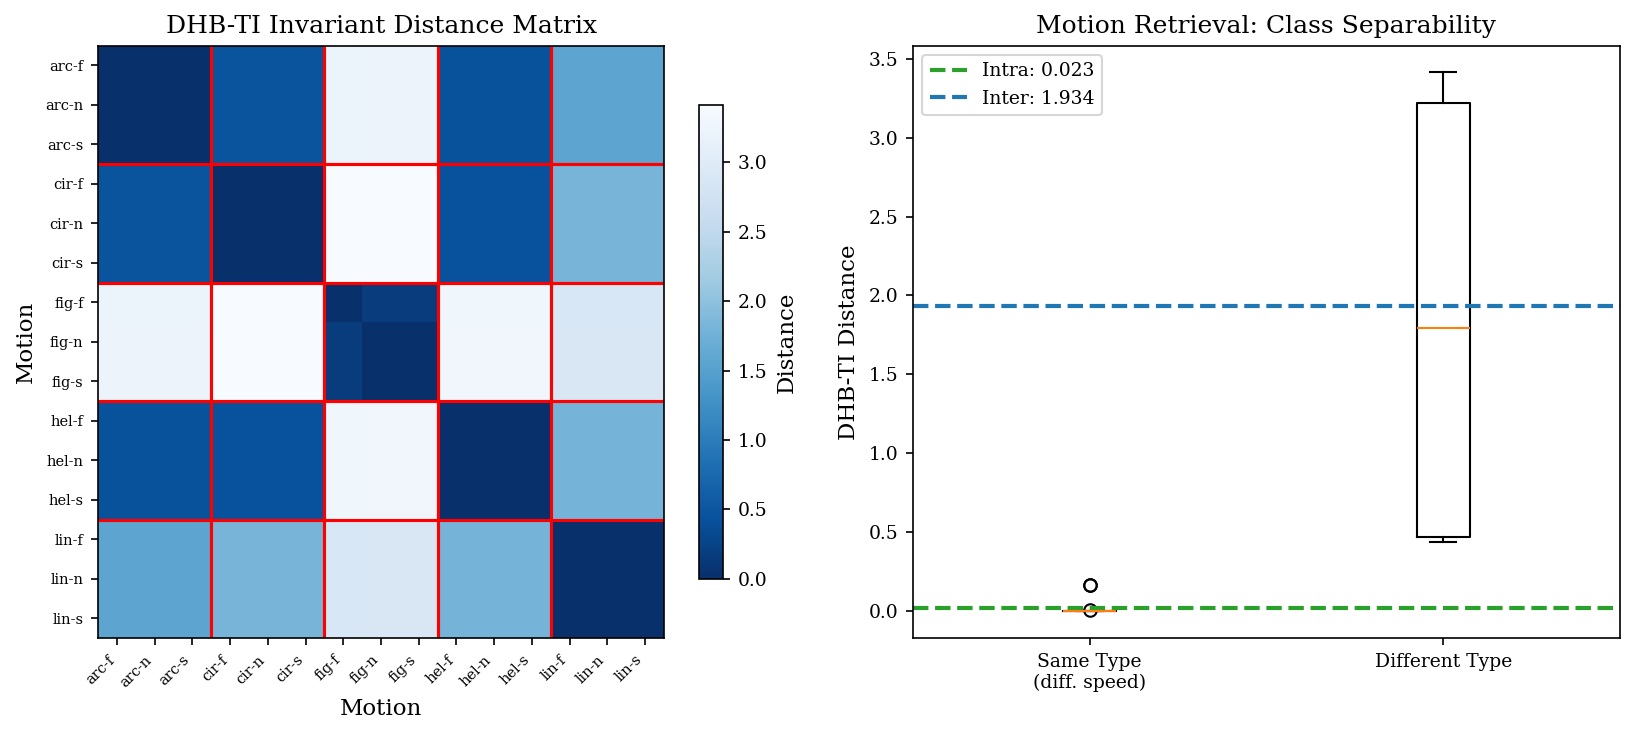

Figure 12 saved.
Separation ratio: 83.6x


In [26]:
# Figure 12: Motion Retrieval
from dhb_xr.encoder.dhb_ti import encode_dhb_dr_ti

def generate_motion(motion_type, n_points=50, speed=1.0, offset=np.array([0, 0, 0])):
    t = np.linspace(0, 2*np.pi/speed, n_points)
    if motion_type == 'circle':
        pos = np.column_stack([0.3*np.cos(t*speed), 0.3*np.sin(t*speed), np.zeros(n_points)])
    elif motion_type == 'helix':
        pos = np.column_stack([0.2*np.cos(t*speed), 0.2*np.sin(t*speed), 0.1*t*speed/(2*np.pi)])
    elif motion_type == 'line':
        pos = np.column_stack([0.3*t*speed/(2*np.pi), 0.1*t*speed/(2*np.pi), 0.05*t*speed/(2*np.pi)])
    elif motion_type == 'arc':
        theta = t*speed*0.7
        pos = np.column_stack([0.25*np.cos(theta), 0.25*np.sin(theta), 0.02*np.sin(theta*2)])
    else:  # figure8
        pos = np.column_stack([0.2*np.sin(t*speed), 0.15*np.sin(2*t*speed), 0.05*np.cos(t*speed)])
    return pos + offset, np.tile([1, 0, 0, 0], (n_points, 1)).astype(float)

# Build database
motion_types = ['circle', 'helix', 'line', 'arc', 'figure8']
M = 30
motion_db = {}
np.random.seed(123)

for mtype in motion_types:
    for variant in ['slow', 'normal', 'fast']:
        speed = {'slow': 0.5, 'normal': 1.0, 'fast': 2.0}[variant]
        n_pts = {'slow': 100, 'normal': 50, 'fast': 25}[variant]
        offset = np.random.randn(3) * 0.1

        pos, quat = generate_motion(mtype, n_points=n_pts, speed=speed, offset=offset)
        result = encode_dhb_dr_ti(pos, quat, M=M, progress_kind='translation')
        invariants = np.hstack([result['linear_motion_invariants'], result['angular_motion_invariants']])

        motion_db[f'{mtype}_{variant}'] = {'type': mtype, 'invariants': invariants}

# Compute distance matrix
keys = list(motion_db.keys())
n = len(keys)
dist_matrix = np.zeros((n, n))

for i, k1 in enumerate(keys):
    for j, k2 in enumerate(keys):
        dist_matrix[i, j] = np.linalg.norm(motion_db[k1]['invariants'] - motion_db[k2]['invariants'])

# Reorder by type
type_order = sorted(range(n), key=lambda i: (motion_db[keys[i]]['type'], keys[i]))
keys_sorted = [keys[i] for i in type_order]
dist_sorted = dist_matrix[np.ix_(type_order, type_order)]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Heatmap
ax1 = axes[0]
im = ax1.imshow(dist_sorted, cmap='Blues_r', aspect='auto')
ax1.set_xticks(range(n))
ax1.set_yticks(range(n))
labels = [k.split('_')[0][:3] + '-' + k.split('_')[1][0] for k in keys_sorted]
ax1.set_xticklabels(labels, fontsize=7, rotation=45, ha='right')
ax1.set_yticklabels(labels, fontsize=7)
ax1.set_title('DHB-TI Invariant Distance Matrix')
ax1.set_xlabel('Motion')
ax1.set_ylabel('Motion')

# Add block boundaries
boundaries = [0]
current_type = motion_db[keys_sorted[0]]['type']
for i, k in enumerate(keys_sorted):
    if motion_db[k]['type'] != current_type:
        boundaries.append(i)
        current_type = motion_db[k]['type']
boundaries.append(n)

for b in boundaries[1:-1]:
    ax1.axhline(b - 0.5, color='red', linewidth=1.5)
    ax1.axvline(b - 0.5, color='red', linewidth=1.5)

plt.colorbar(im, ax=ax1, label='Distance', shrink=0.8)

# Intra vs Inter class
ax2 = axes[1]
intra_dists = []
inter_dists = []

for i, k1 in enumerate(keys):
    for j, k2 in enumerate(keys):
        if i < j:
            if motion_db[k1]['type'] == motion_db[k2]['type']:
                intra_dists.append(dist_matrix[i, j])
            else:
                inter_dists.append(dist_matrix[i, j])

bp = ax2.boxplot([intra_dists, inter_dists], labels=['Same Type\n(diff. speed)', 'Different Type'])
ax2.set_ylabel('DHB-TI Distance')
ax2.set_title('Motion Retrieval: Class Separability')
ax2.axhline(np.mean(intra_dists), color=COLORS['dhb_dr'], linestyle='--', linewidth=2, label=f'Intra: {np.mean(intra_dists):.3f}')
ax2.axhline(np.mean(inter_dists), color=COLORS['original'], linestyle='--', linewidth=2, label=f'Inter: {np.mean(inter_dists):.3f}')
ax2.legend()

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/fig12_motion_retrieval.pdf')
plt.savefig(f'{FIG_DIR}/fig12_motion_retrieval.png')
plt.show()

print('Figure 12 saved.')
print(f'Separation ratio: {np.mean(inter_dists)/np.mean(intra_dists):.1f}x')

---
## Summary: All Figures

| Figure | File | Type | Status |
|--------|------|------|--------|
| Fig 1 | fig1_frame_evolution.pdf | Comparative | Generated |
| Fig 2 | - | Diagram | PLACEHOLDER |
| Fig 3 | - | Diagram | PLACEHOLDER |
| Fig 4 | fig4_invariant_smoothness.pdf | Plot | Generated |
| Fig 5 | fig5_length_preservation.pdf | Plot | Generated |
| Fig 6 | fig6_euler_vs_quaternion.pdf | Plot | Generated |
| Fig 7 | fig7_time_invariance.pdf | Plot | Generated |
| Fig 8 | fig8_gpu_performance.pdf | Benchmark | Generated |
| Fig 9 | fig9_trajectory_adaptation.pdf | Plot | Generated |
| Fig 10 | - | Diagram | PLACEHOLDER |
| Fig 11 | fig11_compression_ratios.pdf | Bar chart | Generated |
| Fig 12 | fig12_motion_retrieval.pdf | Heatmap | Generated |

In [27]:
# List all generated figures
import os
print('Generated figures:')
for f in sorted(os.listdir(FIG_DIR)):
    if f.endswith('.pdf') or f.endswith('.png'):
        path = os.path.join(FIG_DIR, f)
        size_kb = os.path.getsize(path) / 1024
        print(f'  {f} ({size_kb:.1f} KB)')

Generated figures:
  fig11_compression_ratios.pdf (20.1 KB)
  fig11_compression_ratios.png (136.1 KB)
  fig12_motion_retrieval.pdf (24.1 KB)
  fig12_motion_retrieval.png (171.2 KB)
  fig1_frame_evolution.pdf (32.0 KB)
  fig1_frame_evolution.png (735.6 KB)
  fig4_invariant_smoothness.pdf (29.7 KB)
  fig4_invariant_smoothness.png (413.6 KB)
  fig5_length_preservation.pdf (21.8 KB)
  fig5_length_preservation.png (320.6 KB)
  fig6_euler_vs_quaternion.pdf (34.1 KB)
  fig6_euler_vs_quaternion.png (310.1 KB)
  fig7_time_invariance.pdf (28.9 KB)
  fig7_time_invariance.png (530.1 KB)
  fig8_gpu_performance.pdf (23.7 KB)
  fig8_gpu_performance.png (228.1 KB)
  fig9_trajectory_adaptation.pdf (22.4 KB)
  fig9_trajectory_adaptation.png (459.7 KB)
